# Full primary spectrometer

Built from the current `PSCandBC.ipynb`, preserving its source, chopper settings, and comparisons.

Beamline: source → guide 1 → PSC → guide 2 → BC → guide 3 → sample plane.


In [1]:
# CPU-compatible McStas build settings (also apply when rerunning this cell).
import os
import sys
from pathlib import Path

os.environ["MCSTAS_CC_OVERRIDE"] = "/usr/bin/gcc"
os.environ["MCSTAS_MPICC_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpicc")
os.environ["MCSTAS_MPIRUN_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpirun")
os.environ["OMPI_CC"] = "/usr/bin/gcc"
os.environ["MCSTAS_CFLAGS_OVERRIDE"] = "-O2 -march=x86-64 -mtune=generic -std=c99 -D_POSIX_SOURCE -lm"
os.environ["CFLAGS"] = ""
os.environ["LDFLAGS"] = ""

import mcstasscript as ms

instr = ms.McStas_instr(
    "full_primary_spectometer",
    author="McStasScript example",
    origin="Teaching example",
)


In [2]:
pulse_length = 400.0e-6
instr.add_parameter("pulse_length", value=pulse_length,
                    comment="Proton pulse duration for the moderator model [s]")
moderator_tau = 170.0e-6
instr.add_parameter("moderator_tau", value=moderator_tau,
                    comment="Cold moderator decay time used by Source_pulsed [s]")
moderator_n = 5.0
instr.add_parameter("moderator_n", value=moderator_n,
                    comment="Cold moderator pulse-shape parameter used by Source_pulsed")
moderator_time_center = 0.5*pulse_length + moderator_tau*(moderator_n+1.0)/moderator_n
source_frequency = 50.0
instr.add_parameter("source_frequency", value=source_frequency,
                    comment="Source repetition rate [Hz]")
lambda_min = 0.5
instr.add_parameter("lambda_min", value=lambda_min,
                    comment="Minimum source wavelength [Angstrom]")
lambda_max = 10.0
instr.add_parameter("lambda_max", value=lambda_max,
                    comment="Maximum source wavelength [Angstrom]")

l1 = 2.0
instr.add_parameter("l1", value=l1,
                    comment="Length of first guide segment [m]")


Parameter named: 'l1' with value: 2.0
 [dimensionless]
 Length of first guide segment [m]

In [3]:
source = instr.add_component("source", "Source_pulsed")
source.xwidth = 0.042
source.yheight = 0.03
source.Lmin = "lambda_min"
source.Lmax = "lambda_max"
source.t_min = 0.0
source.t_max = 0.004
source.dist = 0.1
source.focus_xw = 0.04
source.focus_yh = 0.04
source.freq = "source_frequency"
source.t_pulse = "pulse_length"
source.T1 = 60.0
source.I1 = "1.75e12/source_frequency"
source.tau1 = "moderator_tau"
source.n_mod = "moderator_n"
source.I_um = "3.82e10/source_frequency"
source.tau_um = 12.0e-6
source.n_um = 5.0
source.chi_um = 0.9
source.kap_um = 2.2

guide = instr.add_component(
    "guide", "Guide", AT=[0, 0, 0.1], RELATIVE="source"
)
guide.w1 = 0.04
guide.h1 = 0.04
guide.w2 = 0.04
guide.h2 = 0.04
guide.l = "l1"
guide.m = 4.0


In [4]:


psc_order = 1
instr.add_parameter("psc_order", value=psc_order,
                    comment="PSC frequency = psc_order times source frequency")
opening_PSC = 36.0
instr.add_parameter("opening_PSC", value=opening_PSC,
                    comment="PSC slit angular opening [degrees]")
chopper_distance = l1+0.12
instr.add_parameter("chopper_distance", value=chopper_distance,
                    comment="Source-to-PSC distance [m]")

psc_lambda_min = 1.0
instr.add_parameter("psc_lambda_min", value=psc_lambda_min,
                    comment="Lower wavelength edge to center on with the PSC [Angstrom]")
psc_lambda_max = 7.0
instr.add_parameter("psc_lambda_max", value=psc_lambda_max,
                    comment="Upper wavelength edge to center on with the PSC [Angstrom]")
lambda_center = 0.5 * (psc_lambda_min + psc_lambda_max)


In [5]:
instr.add_declare_var("double", "nu_PSC")
instr.add_declare_var("double", "PSC_order")
instr.add_declare_var("double", "actual_width_PSC")
instr.add_declare_var("double", "psc_source_center")
instr.add_declare_var("double", "psc_phase_lambda")
instr.add_declare_var("double", "psc_phase_time")
instr.add_declare_var("double", "psc_phase_deg")
instr.add_declare_var("double", "psc_t_start")
instr.add_declare_var("double", "psc_t_end")
instr.add_declare_var("double", "psc_target_width")
instr.add_declare_var("double", "psc_band_min")
instr.add_declare_var("double", "psc_band_max")
instr.add_declare_var("double", "psc_max_order")


Declare variable: 'psc_max_order' of type double

In [6]:
instr.append_initialize(
    'if (moderator_tau <= 0 || moderator_n <= 1 || source_frequency <= 0 || psc_order < 1 || fabs(psc_order-floor(psc_order+0.5)) > 1e-6 || opening_PSC <= 0 || opening_PSC >= 360 || psc_lambda_min < lambda_min || psc_lambda_max > lambda_max || psc_lambda_min <= 0 || psc_lambda_max <= psc_lambda_min) { fprintf(stderr, "PSC band must be within the source range; order, source frequency and slit opening must be valid\\n"); exit(1); }'
)
instr.append_initialize("psc_band_min = psc_lambda_min;")
instr.append_initialize("psc_band_max = psc_lambda_max;")
instr.append_initialize("psc_phase_lambda = (psc_band_min + psc_band_max)/2.0;")
instr.append_initialize("PSC_order = psc_order;")
instr.append_initialize("nu_PSC = PSC_order*source_frequency;")
instr.append_initialize("actual_width_PSC = opening_PSC/(360.0*nu_PSC);")
instr.append_initialize("psc_source_center = 0.5*pulse_length + moderator_tau*(moderator_n+1.0)/moderator_n;")
instr.append_initialize("psc_t_start = psc_source_center + chopper_distance*psc_band_min/3956.0346;")
instr.append_initialize("psc_t_end = psc_source_center + chopper_distance*psc_band_max/3956.0346;")
instr.append_initialize("psc_target_width = pulse_length + chopper_distance*(psc_band_max-psc_band_min)/3956.0346;")
instr.append_initialize("psc_max_order = floor(opening_PSC/(360.0*source_frequency*psc_target_width));")
instr.append_initialize('if (actual_width_PSC + 1e-12 < psc_target_width) { printf("WARNING: PSC gate is narrower than the nominal source-pulse plus target-band arrival span; band edges will be clipped\\n"); }')
instr.append_initialize("psc_phase_time = 0.5*(psc_t_start + psc_t_end);")
instr.append_initialize("psc_phase_deg = fmod(360.0*nu_PSC*psc_phase_time, 360.0);")
instr.append_initialize('printf("PSC order=%g, rate=%g Hz (%g rpm), gate=%g us, nominal gate requirement=%g us, largest nominal order=%g; source center=%g ms; phase=%g deg at t=%g ms\\n", PSC_order, nu_PSC, 60.0*nu_PSC, actual_width_PSC*1e6, psc_target_width*1e6, psc_max_order, 1e3*psc_source_center, psc_phase_deg, 1e3*psc_phase_time);')
instr.append_initialize(
    'if (chopper_distance < 0.1 + l1 + 0.02) { printf("PSC is too close to guide 1; increase chopper_distance or reduce l1\\n"); exit(1); }'
)


In [7]:

psc = instr.add_component(
    "PSC", "DiskChopper",
    AT=[0, 0, "chopper_distance"], RELATIVE="source",
)
psc.radius = 0.25
psc.yheight = 0.065  
psc.theta_0 = "opening_PSC"
psc.nu = "nu_PSC"
psc.nslit = 1
psc.phase = "psc_phase_deg"
psc.abs_out = 1
psc.verbose = 1  # print the calculated rate and gate settings at run time


In [8]:
lambda_band_min = 2.0
instr.add_parameter("lambda_band_min", value=lambda_band_min,
                    comment="Lower edge of selected BC wavelength band [Angstrom]")
lambda_band_max = 4.0
instr.add_parameter("lambda_band_max", value=lambda_band_max,
                    comment="Upper edge of selected BC wavelength band [Angstrom]")
lambda_bandwidth = lambda_band_max - lambda_band_min
guide2_length = 10.0
instr.add_parameter("guide2_length", value=guide2_length,
                    comment="Length of guide section between PSC and BC [m]")


Parameter named: 'guide2_length' with value: 10.0
 [dimensionless]
 Length of guide section between PSC and BC [m]

In [9]:

guide2 = instr.add_component(
    "guide2", "Guide", AT=[0, 0, 0.02], RELATIVE="PSC"
)
guide2.w1 = 0.04
guide2.h1 = 0.04
guide2.w2 = 0.04
guide2.h2 = 0.04
guide2.l = "guide2_length"
guide2.m = 4.0


In [10]:
instr.add_declare_var("double", "L_PSC_BC")
instr.add_declare_var("double", "gate_width_BC")
instr.add_declare_var("double", "opening_BC")
instr.add_declare_var("double", "nu_BC")
instr.add_declare_var("double", "lambda_bandwidth")
instr.add_declare_var("double", "lambda_band_center")
instr.add_declare_var("double", "bc_target_width")
instr.add_declare_var("double", "bc_max_order")
instr.add_declare_var("double", "bc_phase_time")
instr.add_declare_var("double", "bc_phase_deg")


Declare variable: 'bc_phase_deg' of type double

In [11]:
instr.append_initialize('if (lambda_band_min < lambda_min || lambda_band_max > lambda_max || lambda_band_min <= 0 || lambda_band_max <= lambda_band_min) { fprintf(stderr, "Requested BC band must lie within source wavelength limits\\n"); exit(1); }')
instr.append_initialize("lambda_bandwidth = lambda_band_max - lambda_band_min;")
instr.append_initialize("lambda_band_center = (lambda_band_min + lambda_band_max)/2.0;")
instr.append_initialize("L_PSC_BC = guide2_length + 0.04;")
instr.append_initialize("opening_BC = 120.0;")
instr.append_initialize("bc_target_width = pulse_length + (chopper_distance+L_PSC_BC)*lambda_bandwidth/3956.0346;")
instr.append_initialize("bc_max_order = floor(opening_BC/(360.0*source_frequency*bc_target_width));")
instr.append_initialize('if (bc_max_order < 1) { fprintf(stderr, "Selected wavelength band is too broad for a source-synchronized BC with a 120 degree opening\\n"); exit(1); }')
instr.append_initialize("nu_BC = bc_max_order*source_frequency;")
instr.append_initialize("gate_width_BC = opening_BC/(360.0*nu_BC);")
instr.append_initialize("bc_phase_time = psc_source_center + (chopper_distance+L_PSC_BC)*lambda_band_center/3956.0346;")
instr.append_initialize("bc_phase_deg = fmod(360.0*nu_BC*bc_phase_time, 360.0);")
instr.append_initialize('printf("BC fixed opening=%g deg; selected band=%g-%g A; required window=%g us; harmonic=%g; rate=%g Hz; actual gate=%g us; phase=%g deg at t=%g ms\\n", opening_BC, lambda_band_min, lambda_band_max, bc_target_width*1e6, bc_max_order, nu_BC, gate_width_BC*1e6, bc_phase_deg, 1e3*bc_phase_time);')
instr.append_initialize('if (opening_BC >= 360.0) { fprintf(stderr, "BC opening must be less than 360 degrees\\n"); exit(1); }')


In [12]:

bc = instr.add_component(
    "BC", "DiskChopper", AT=[0, 0, "L_PSC_BC"], RELATIVE="PSC"
)
bc.radius = 0.25
bc.yheight = 0.065
bc.theta_0 = "opening_BC"
bc.nu = "nu_BC"
bc.nslit = 1
bc.phase = "bc_phase_deg"
bc.abs_out = 1
bc.verbose = 1


In [13]:
# Monitor pair immediately after the BC.
lambda_after_BC = instr.add_component(
    "lambda_after_BC", "L_monitor", AT=[0, 0, 0.005], RELATIVE="BC"
)
lambda_after_BC.xwidth = 0.04
lambda_after_BC.yheight = 0.04
lambda_after_BC.nL = 100
lambda_after_BC.Lmin = 0.5
lambda_after_BC.Lmax = 10.0
lambda_after_BC.restore_neutron = 1




## Extend the primary spectrometer to the sample

Add guide 3 after the bandwidth chopper, then measure the beam at the sample plane.

| Parameter | Default | Meaning |
| --- | --- | --- |
| `l3` | 1.0 m | Length of the third straight guide. |
| `d_guide_sample` | 0.1 m | Free-flight distance from the **exit of guide 3** to the sample plane. |

Guide 3 starts 20 mm after the BC and uses the same 40 × 40 mm aperture and `m = 4` as the other guides. Its exit is at `l3` relative to its entrance. The sample plane is therefore at `l3 + d_guide_sample` relative to `guide3`.

The total source-to-sample distance is `chopper_distance + guide2_length + 0.04 + 0.02 + l3 + d_guide_sample`. Change the two defaults below to match your intended geometry, then rebuild the instrument from the top.


In [14]:
l3 = 23.0

instr.add_parameter("l3", value=l3,
                    comment="Length of guide 3 after the BC [m]")
d_guide_sample = 1.5
instr.add_parameter("d_guide_sample", value=d_guide_sample,
                    comment="Distance from guide 3 exit to sample plane [m]")
instr.append_initialize('if (l3 <= 0 || d_guide_sample < 0) { fprintf(stderr, "Guide 3 length must be positive and sample gap non-negative\\n"); exit(1); }')

guide3 = instr.add_component(
    "guide3", "Guide", AT=[0, 0, 0.02], RELATIVE="BC"
)
guide3.w1 = 0.04
guide3.h1 = 0.04
guide3.w2 = 0.04
guide3.h2 = 0.04
guide3.l = "l3"
guide3.m = 4.0

sample_position = instr.add_component(
    "sample_position", "Arm",
    AT=[0, 0, "l3 + d_guide_sample"], RELATIVE="guide3"
)


## Measure the beam at the sample position

All four monitors are placed at `sample_position`

1. **Divergence:** 
2. **PSD:** 
3. **TOF:** 
4. **Wavelength:** 

In [15]:
divergence_sample = instr.add_component(
    "divergence_sample", "Divergence_monitor",
    AT=[0, 0, 0], RELATIVE="sample_position"
)
divergence_sample.xwidth = 0.04
divergence_sample.yheight = 0.04
divergence_sample.nh = 100
divergence_sample.nv = 100
divergence_sample.maxdiv_h = 2.0
divergence_sample.maxdiv_v = 2.0
divergence_sample.restore_neutron = 1

psd_sample = instr.add_component(
    "psd_sample", "PSD_monitor",
    AT=[0, 0, 0], RELATIVE="sample_position"
)
psd_sample.xwidth = 0.1
psd_sample.yheight = 0.1
psd_sample.nx = 100
psd_sample.ny = 100
psd_sample.restore_neutron = 1

tof_sample = instr.add_component(
    "tof_sample", "TOF_monitor",
    AT=[0, 0, 0], RELATIVE="sample_position"
)
tof_sample.xwidth = 0.04
tof_sample.yheight = 0.04
tof_sample.nt = 1000
tof_sample.tmin = 0.0
tof_sample.tmax = "1e6 * fmax(1.0/source_frequency, 0.004 + (chopper_distance + guide2_length + 0.06 + l3 + d_guide_sample)*lambda_max/3956.0346)"
tof_sample.restore_neutron = 1

lambda_sample = instr.add_component(
    "lambda_sample", "L_monitor",
    AT=[0, 0, 0], RELATIVE="sample_position"
)
lambda_sample.xwidth = 0.04
lambda_sample.yheight = 0.04
lambda_sample.nL = 100
lambda_sample.Lmin = "lambda_min"
lambda_sample.Lmax = "lambda_max"
lambda_sample.restore_neutron = 1


## 12. Run the complete beamline



---- Found 1 places in McStas output with keyword 'error'. 

[mac-pro:3020351] Set MCA parameter "orte_base_help_aggregate" to 0 to see all help / error messages
*** TRACE end *** 
Detector: lambda_after_BC_I=6.96542e+09 lambda_after_BC_ERR=1.68976e+07 lambda_after_BC_N=1.81784e+06 "lambda_after_BC.dat"
Detector: divergence_sample_I=2.3675e+09 divergence_sample_ERR=1.05116e+07 divergence_sample_N=452300 "divergence_sample.dat"
Detector: psd_sample_I=3.58663e+09 psd_sample_ERR=1.23693e+07 psd_sample_N=1.60453e+06 "psd_sample.dat"
Detector: tof_sample_I=2.3675e+09 tof_sample_ERR=1.05116e+07 tof_sample_N=452300 "tof_sample.dat"
Detector: lambda_sample_I=2.3675e+09 lambda_sample_ERR=1.05116e+07 lambda_sample_N=452300 "lambda_sample.dat"
INFO: Placing instr file copy full_primary_spectometer.instr in dataset /run/media/kyriakos2013/Crucial_X9/SCHOOL/solutions/full_primary/full_primary_spectometer
INFO: Placing generated c-code copy full_primary_spectometer.c in dataset /run/media/kyriakos20

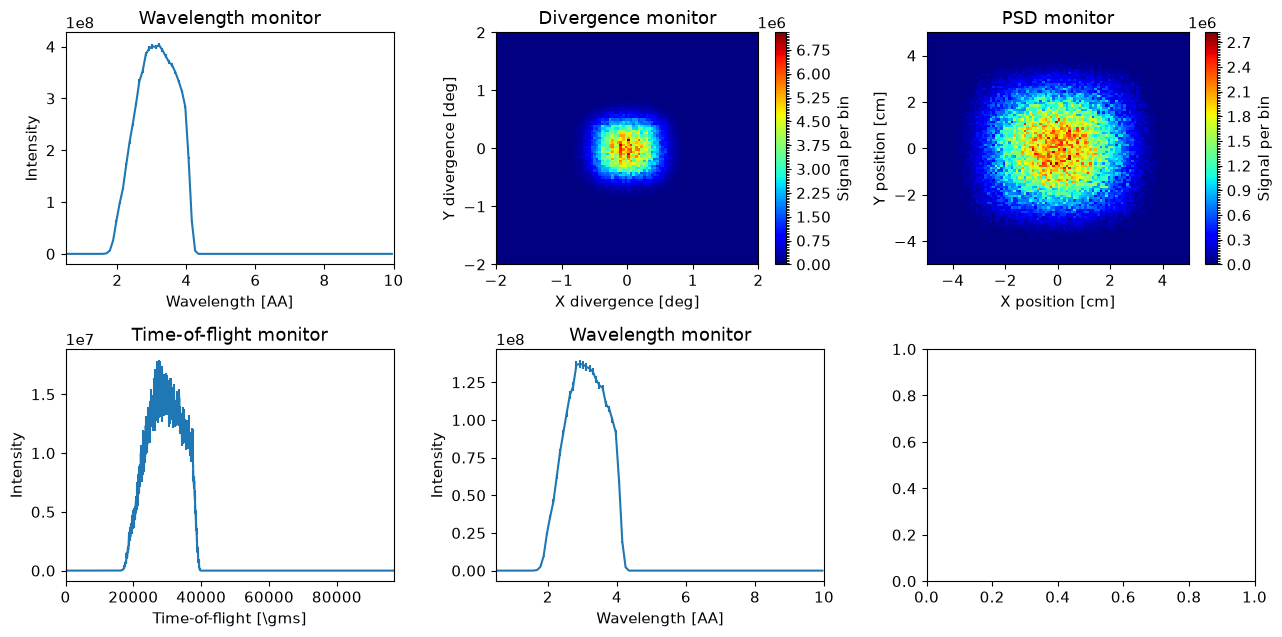

In [16]:
# CPU-compatible McStas build settings (also apply when rerunning this cell).
import os
import sys
from pathlib import Path

os.environ["MCSTAS_CC_OVERRIDE"] = "/usr/bin/gcc"
os.environ["MCSTAS_MPICC_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpicc")
os.environ["MCSTAS_MPIRUN_OVERRIDE"] = str(Path(sys.prefix) / "bin" / "mpirun")
os.environ["OMPI_CC"] = "/usr/bin/gcc"
os.environ["MCSTAS_CFLAGS_OVERRIDE"] = "-O2 -march=x86-64 -mtune=generic -std=c99 -D_POSIX_SOURCE -lm"
os.environ["CFLAGS"] = ""
os.environ["LDFLAGS"] = ""

instr.settings(force_compile=True, ncount=1e9, mpi=12)
data=instr.backengine()
ms.make_sub_plot(data)